In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy, pylab
import seaborn as sns
import palettable
def set_plotting_style():
    sns.set_context('talk')
    sns.set_theme(font_scale=1.5)
    sns.set_style('ticks')
    pylab.rcParams.update(
        {
            'text.usetex': False,
            'font.family': 'stixgeneral',
            'mathtext.fontset': 'stix',
            'axes.grid' : True,
            'grid.linestyle' : '--',
            'grid.color' : '#bbbbbb'

        }
    )

    pylab.rcParams['axes.linewidth'] = 1
    pylab.rcParams['axes.prop_cycle'] = pylab.cycler(color=palettable.cartocolors.diverging.TealRose_7.mpl_colors)

    return

set_plotting_style()

In [2]:
import os, glob
import corner, pandas
from plot_utils import new_rcParams, PHI
from cosmology import FIDUCIAL_COSMOLOGY

os.makedirs('plots', exist_ok=True)

# Spectral sirens with FullPop, edges fixed
Term-I population Fisher (zero measurement error), one year, SNR $\geq 10$, with $(H_0, \Omega_m, w_0)$ marginalised jointly with the free population parameters. Networks: CE40+CE20+ET-D and CE40+CE20+LIA+ (A+, 7 Hz).

The edge parameters are held fixed at the injected values, so no derivative is taken across an edge:
* **all edges fixed:** $m_{\rm NS,min}, m_{\rm NS,max}, m_{\rm BH,min}, m_{\rm BH,max}, m_{\rm UMG,min}, m_{\rm UMG,max}$ and the sharpness exponents $\eta_0\ldots\eta_5$,
* **NSmin–BHmax fixed:** $m_{\rm NS,min}, m_{\rm NS,max}, m_{\rm BH,min}, m_{\rm BH,max}$ and $\eta_0\ldots\eta_4$.

A parameter whose score is the same on every event of a sub-sample (e.g. $\alpha_2$ for BNS alone: no event above $m_{\rm BH,min}$) carries no information there and is pinned as well; it is listed as *unconstrained*.

Every run is one file in `spectral_sirens_output/`, written by
```
spectral_sirens_forecast.py --mass-model fullpop --network CE4020{ETD,LIA} [--bns] [--bhns] [--bbh] --fix {alledges,edges} --term-one-only --snr-thresholds 10
```

In [3]:
networks = {'CE4020ETD': 'CE40+CE20+ET-D', 'CE4020LIA': 'CE40+CE20+LIA+'}
fixed_sets = {'alledges': 'all edges fixed', 'edges': 'NSmin–BHmax fixed'}
populations = {'bns': 'BNS', 'bhns': 'NSBH', 'bbh': 'BBH', 'bns+bhns': 'BNS + NSBH', 'bns+bbh': 'BNS + BBH',
               'bhns+bbh': 'NSBH + BBH', 'bns+bhns+bbh': 'BNS + NSBH + BBH'}
cosmology_names = ['H0', 'Om', 'w0']
cosmology_labels = [r'$H_0\ [{\rm km\,s^{-1}\,Mpc^{-1}}]$', r'$\Omega_m$', r'$w_0$']
palette = palettable.cartocolors.diverging.TealRose_7.mpl_colors
rng = numpy.random.default_rng(250114)

def load_run(network, pops, fixed_set):
    data = numpy.load(f'spectral_sirens_output/fullpop_{network}_{pops}_fix_{fixed_set}_snr10.npz')
    return {'names': [str(name) for name in data['parameter_names']], 'fiducial': data['fiducial'],
            'covariance': data['covariance'], 'n_events': int(data['n_events']),
            'unconstrained': [str(name) for name in data['unconstrained']]}

def sigma(run, name):
    index = run['names'].index(name)
    return numpy.sqrt(run['covariance'][index, index])

def correlation(run):
    scale = numpy.sqrt(numpy.diag(run['covariance']))
    return run['covariance'] / numpy.outer(scale, scale)

def cosmology_draws(run, size=60000):
    index = [run['names'].index(name) for name in cosmology_names]
    mean = numpy.array([FIDUCIAL_COSMOLOGY[name] for name in cosmology_names])
    with numpy.errstate(all='ignore'):  # spurious matmul warnings from macOS Accelerate
        return rng.multivariate_normal(mean, run['covariance'][numpy.ix_(index, index)], size)

## Which population measures cosmology best?
CE40+CE20+LIA+, all edges fixed, every combination of the three catalogues. The last column scales $\sigma(H_0)$ to 1000 detected events, $\sigma(H_0)\sqrt{N/1000}$, which separates *information per event* from *number of events*.

In [4]:
by_population = {pops: load_run('CE4020LIA', pops, 'alledges') for pops in populations}

pandas.DataFrame({populations[pops]: {
    'events': run['n_events'],
    'free parameters': len(run['names']),
    'unconstrained': ', '.join(run['unconstrained']) or '-',
    'sigma(H0) [km/s/Mpc]': round(sigma(run, 'H0'), 4),
    'sigma(Om)': round(sigma(run, 'Om'), 5),
    'sigma(w0)': round(sigma(run, 'w0'), 4),
    'sigma(H0) per 1000 events': round(sigma(run, 'H0') * numpy.sqrt(run['n_events'] / 1000), 3)}
    for pops, run in by_population.items()}).T

,events,free parameters,unconstrained,sigma(H0) [km/s/Mpc],sigma(Om),sigma(w0),sigma(H0) per 1000 events
BNS,36928,14,"alpha_dip, alpha_2, A, A2, beta_pair_2",0.9842,0.00613,0.0792,5.981
NSBH,25623,18,beta_pair_2,1.6878,0.00923,0.1151,8.544
BBH,31368,19,-,2.3677,0.01557,0.1208,13.261
BNS + NSBH,62551,18,beta_pair_2,0.8025,0.00467,0.0614,6.347
BNS + BBH,68296,19,-,0.7803,0.00461,0.0571,6.449
NSBH + BBH,56991,19,-,1.2466,0.00707,0.0802,9.411
BNS + NSBH + BBH,93919,19,-,0.7031,0.00405,0.0507,6.814


BNS alone is numerically singular even after pinning: at $m < 2\,M_\odot$ only the far tails of the two Gaussian peaks contribute, and their parameters are nearly degenerate, so the inversion falls back to a pseudo-inverse. $\sigma(H_0)$ does not depend on that: pinning peak 2, or both peaks, gives 0.991 and 0.970 against 0.984.

Text(0.5, 1.01, 'CE40+CE20+LIA+, all edges fixed')

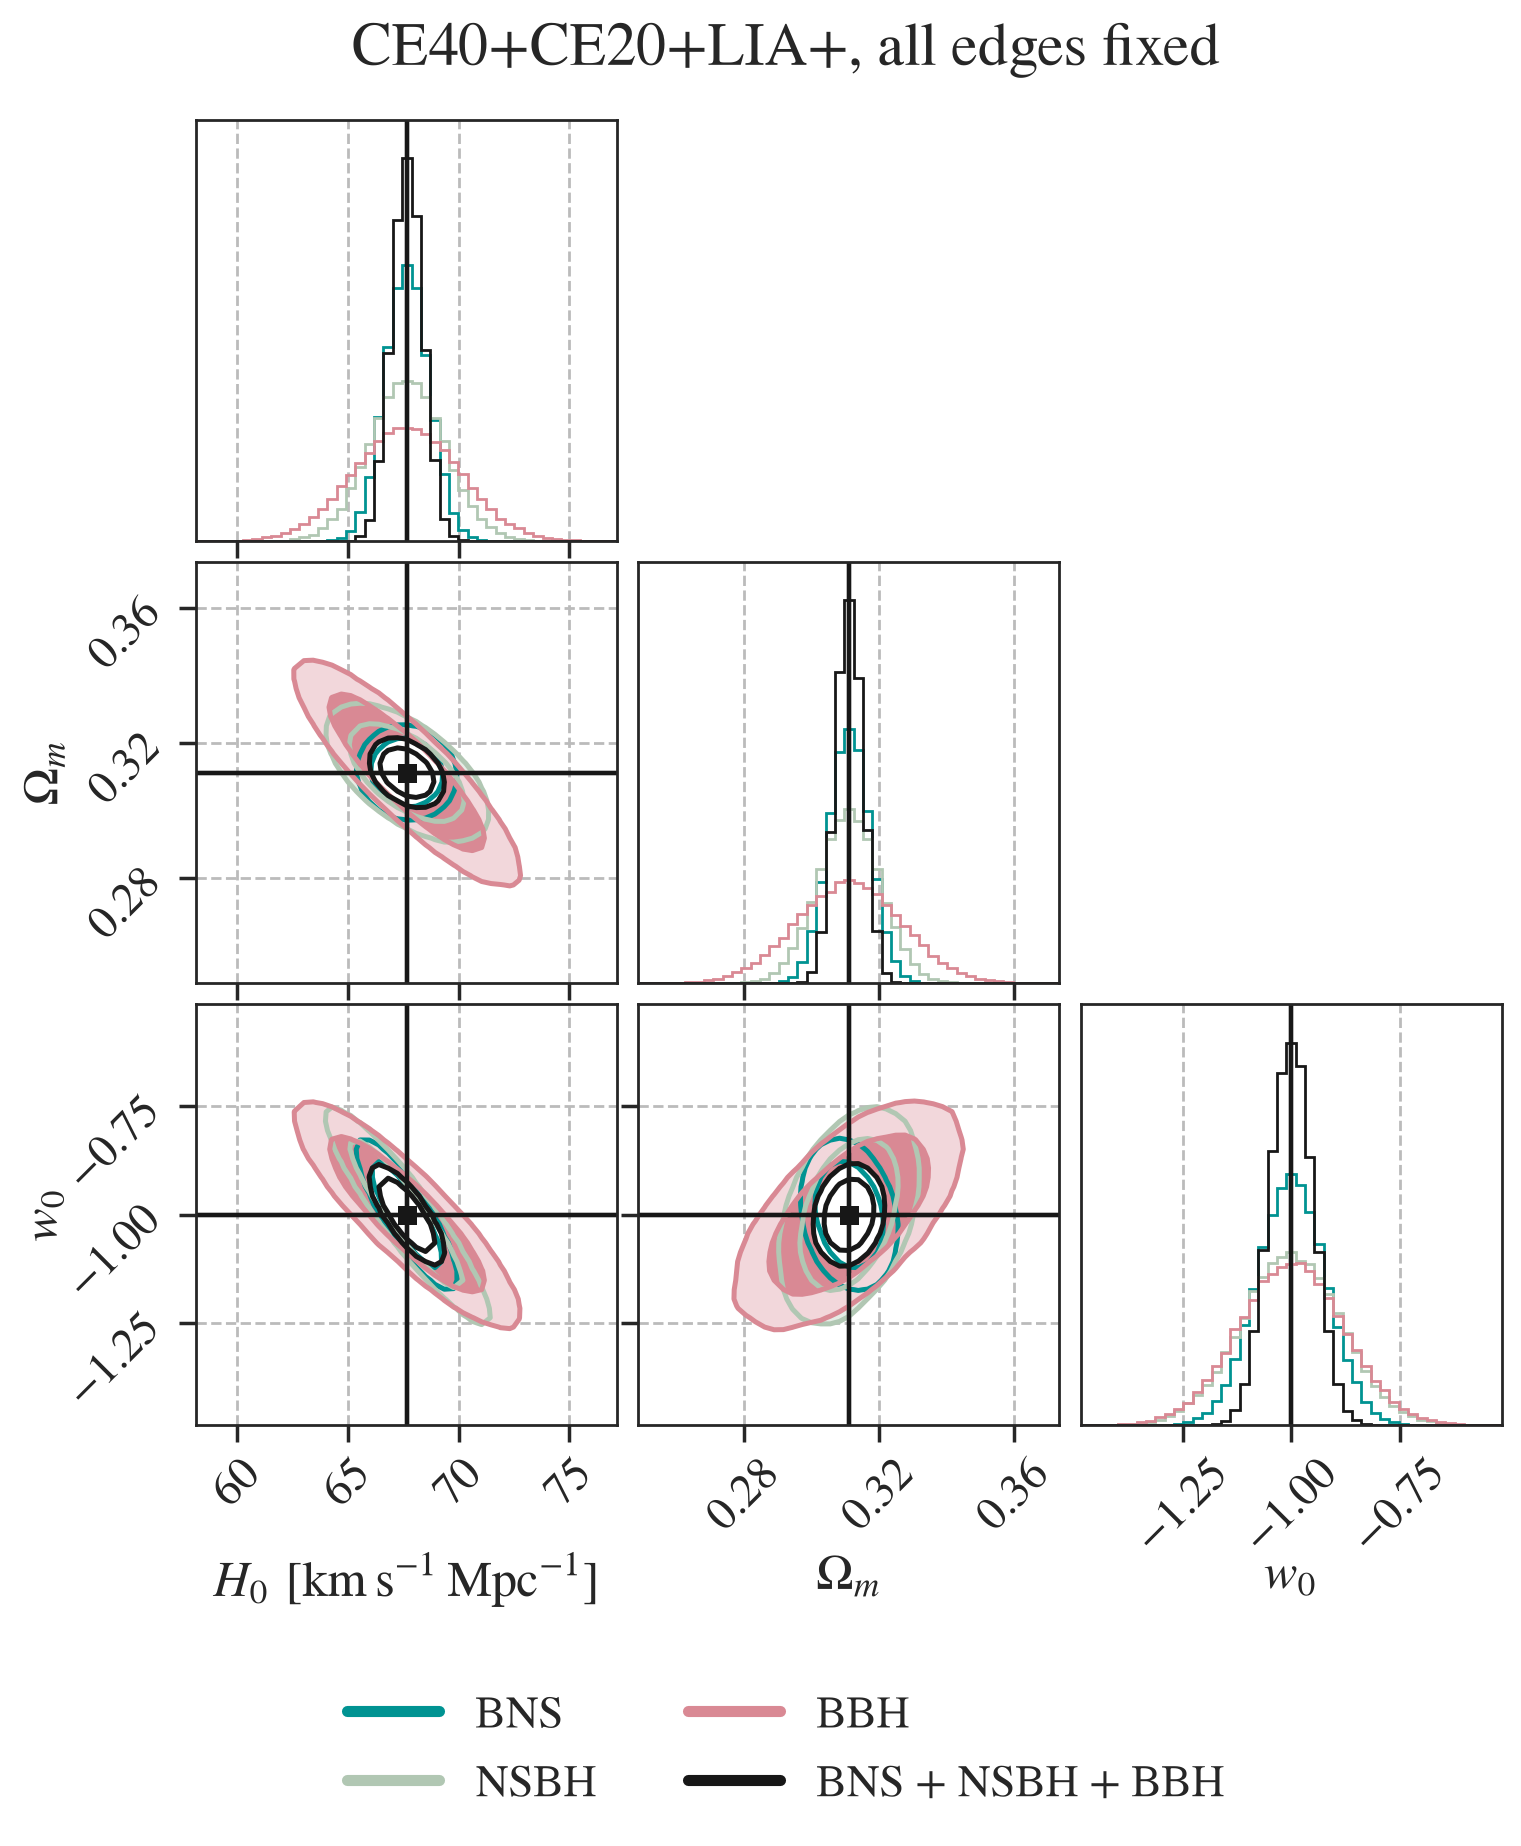

In [5]:
population_colors = {'bns': palette[0], 'bhns': palette[2], 'bbh': palette[5], 'bns+bhns+bbh': '#171717'}
mean = numpy.array([FIDUCIAL_COSMOLOGY[name] for name in cosmology_names])
draws = {pops: cosmology_draws(by_population[pops]) for pops in population_colors}
widest = numpy.max([sample.std(axis=0) for sample in draws.values()], axis=0)
ranges = [(m - 4 * w, m + 4 * w) for m, w in zip(mean, widest)]

# pylab.rcParams.update(new_rcParams(width='page', aspect_ratio=1))
figure = pylab.figure(figsize=(8, 8))
for pops, sample in draws.items():
    
    corner.corner(sample, 
                  fig=figure, 
                  labels=cosmology_labels, 
                  color=population_colors[pops], 
                  range=ranges,
                  truths=list(mean), 
                  truth_color='#171717', 
                  levels=(0.68, 0.90),
                  bins=45, 
                  smooth=0.9,
                  plot_datapoints=False, 
                  plot_density=False, 
                  fill_contours=pops != 'bns+bhns+bbh', 
                  max_n_ticks=4,
                  contour_kwargs={'linewidths': 1.8})
    
_ = figure.legend(handles=[pylab.Line2D([], [], color=color, lw=4, label=populations[pops])
                           for pops, color in population_colors.items()],
                  loc='upper center', frameon=False, ncols=2, bbox_to_anchor=(0.5, -0.01))
figure.suptitle('CE40+CE20+LIA+, all edges fixed', y=1.01)
# pylab.savefig('plots/cosmology_corner_by_population_snr10.pdf', bbox_inches='tight')

## Networks and fixed sets, whole CBC (BNS + NSBH + BBH)

In [6]:
runs = {(tag, fixed_set): load_run(tag, 'bns+bhns+bbh', fixed_set) for tag in networks for fixed_set in fixed_sets}

summary = pandas.DataFrame({(networks[tag], fixed_sets[fixed_set]): {
    'events': run['n_events'],
    'free parameters': len(run['names']),
    'sigma(H0) [km/s/Mpc]': sigma(run, 'H0'),
    'sigma(Om)': sigma(run, 'Om'),
    'sigma(w0)': sigma(run, 'w0'),
    'corr(H0, Om)': correlation(run)[run['names'].index('H0'), run['names'].index('Om')],
    'corr(H0, w0)': correlation(run)[run['names'].index('H0'), run['names'].index('w0')]}
    for (tag, fixed_set), run in runs.items()}).T

summary.astype({'events': int, 'free parameters': int}).round(4)

events  free parameters  \
CE40+CE20+ET-D all edges fixed    110580               19   
               NSmin–BHmax fixed  110580               22   
CE40+CE20+LIA+ all edges fixed     93919               19   
               NSmin–BHmax fixed   93919               22   

                                  sigma(H0) [km/s/Mpc]  sigma(Om)  sigma(w0)  \
CE40+CE20+ET-D all edges fixed                  0.6681     0.0038     0.0473   
               NSmin–BHmax fixed                0.6683     0.0038     0.0474   
CE40+CE20+LIA+ all edges fixed                  0.7031     0.0040     0.0507   
               NSmin–BHmax fixed                0.7033     0.0040     0.0507   

                                  corr(H0, Om)  corr(H0, w0)  
CE40+CE20+ET-D all edges fixed         -0.5191       -0.9586  
               NSmin–BHmax fixed       -0.5181       -0.9586  
CE40+CE20+LIA+ all edges fixed         -0.4699       -0.9561  
               NSmin–BHmax fixed       -0.4687       -0.9562

### $(H_0, \Omega_m, w_0)$, whole CBC
Gaussian draws from the joint covariance, marginalised over every free population parameter; 68% and 90% contours. Colour marks the network, solid lines are all edges fixed and dashed lines NSmin–BHmax fixed (the two fixed sets lie on top of each other).

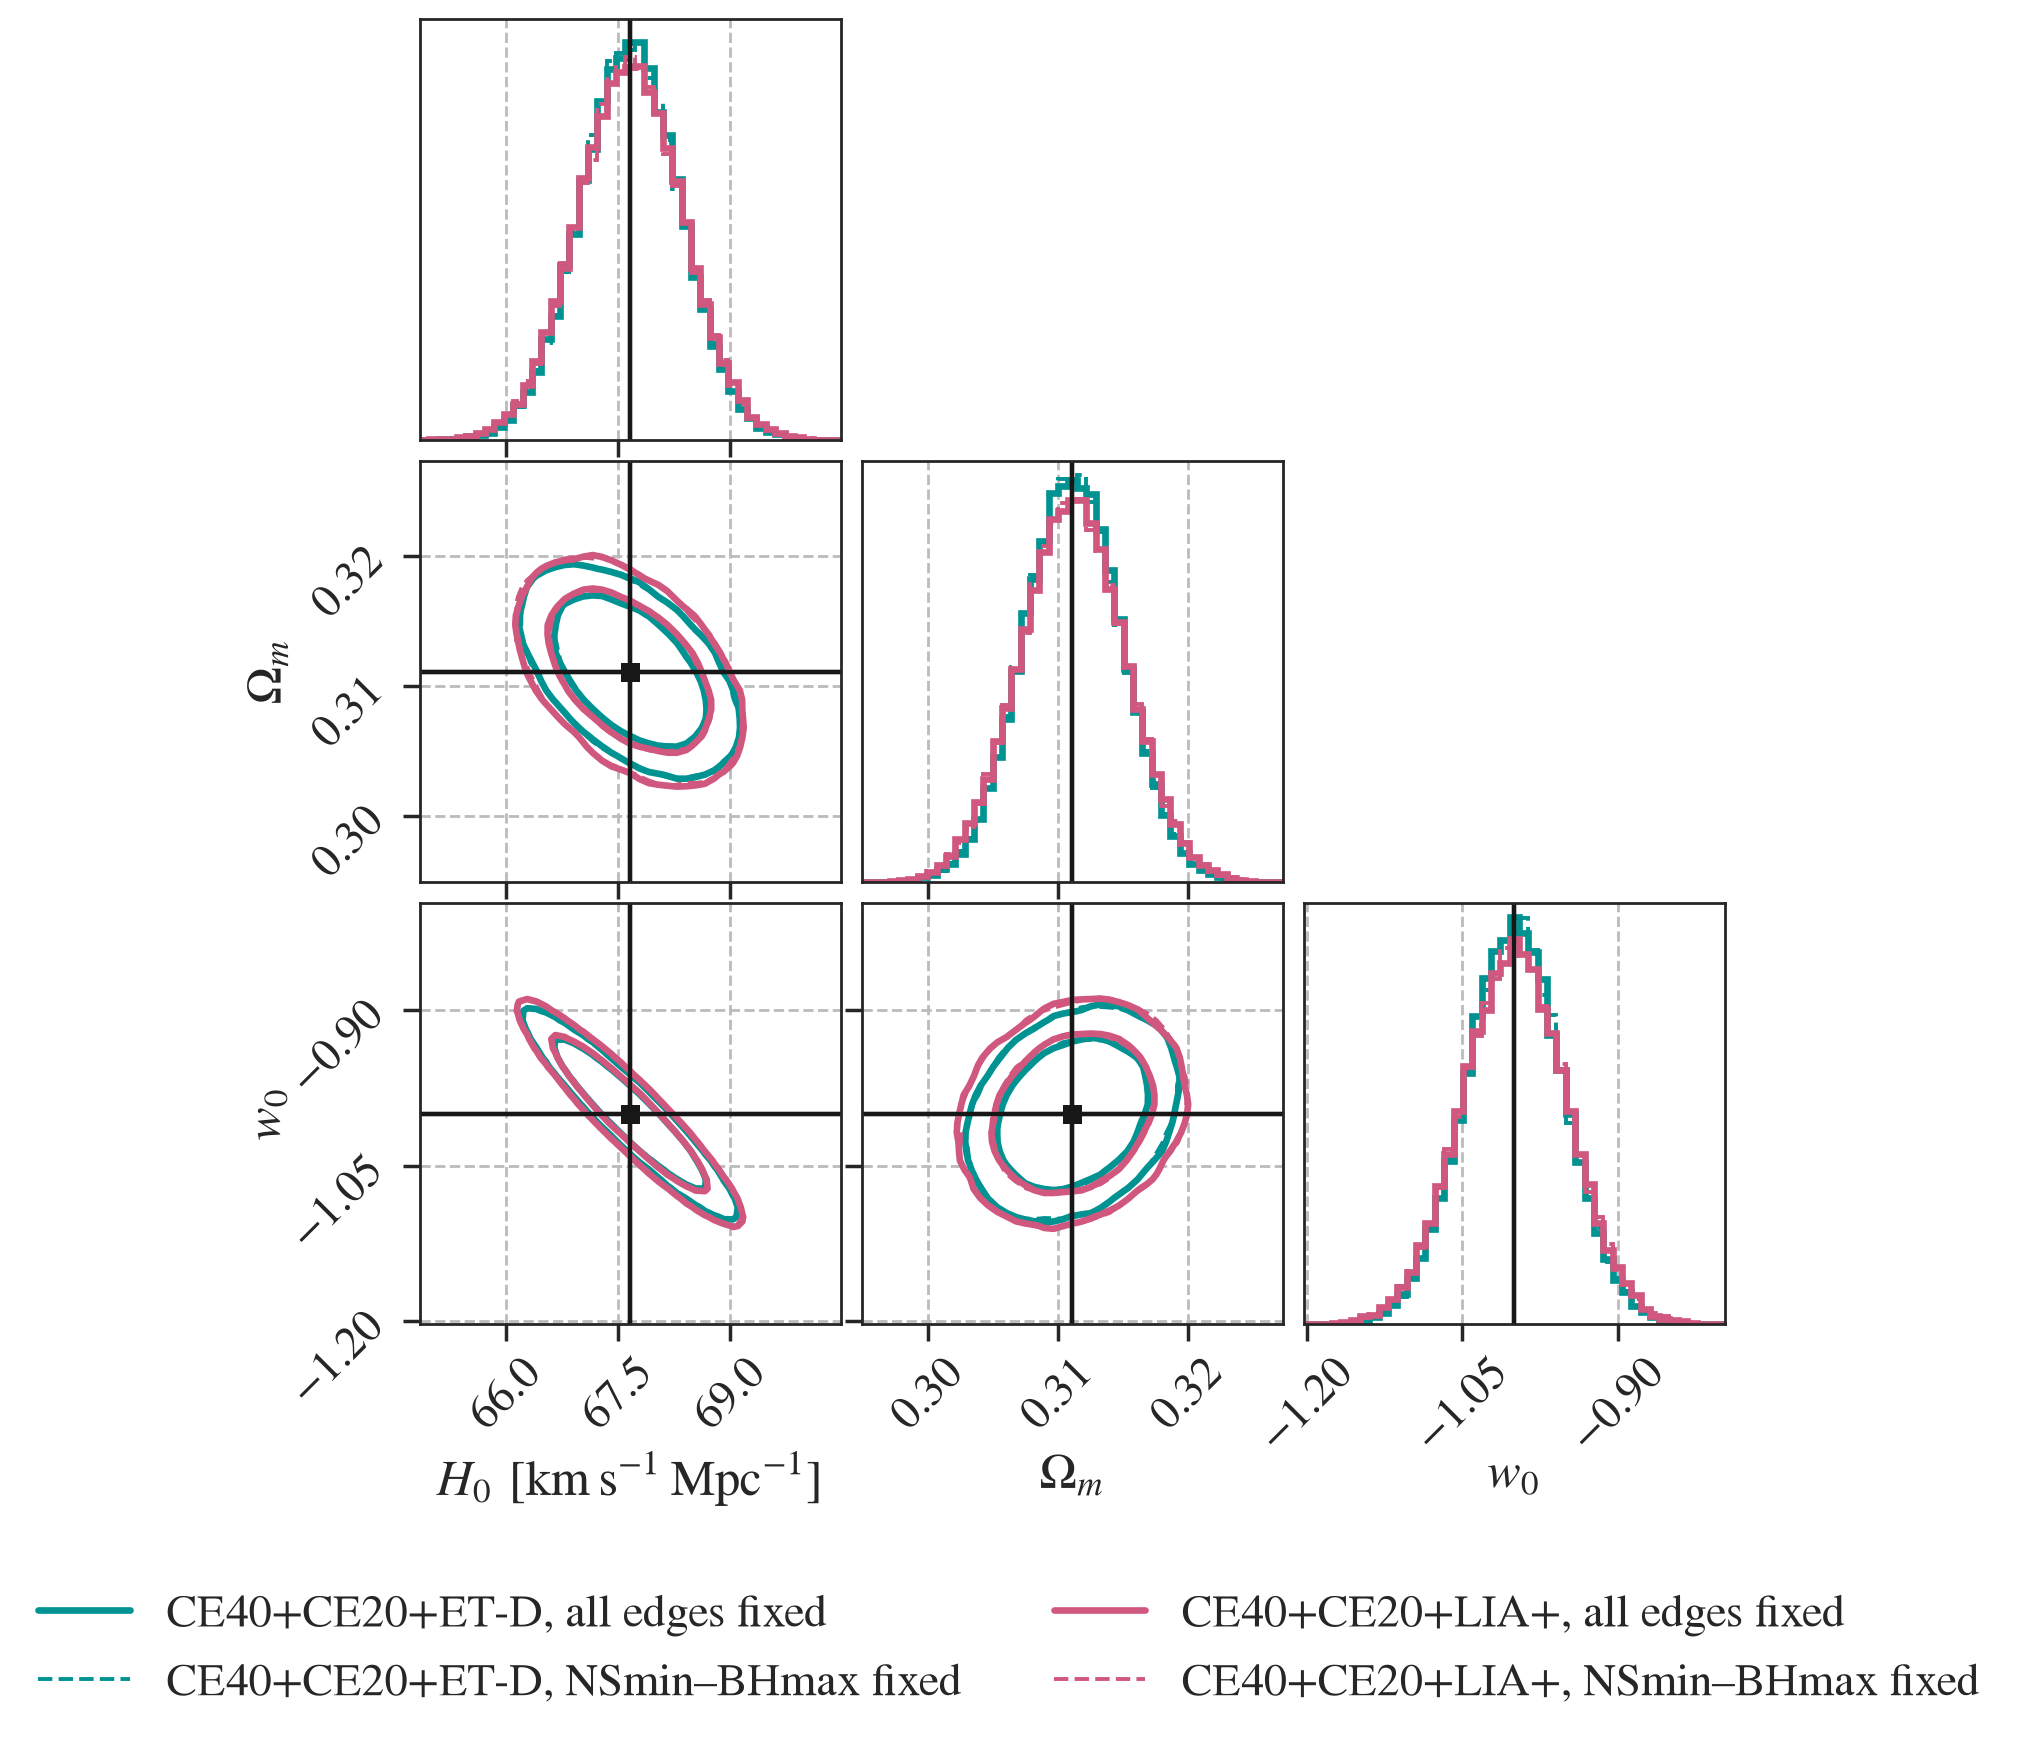

In [7]:
colors = {'CE4020ETD': palette[0], 'CE4020LIA': palette[6]}
draws = {key: cosmology_draws(run) for key, run in runs.items()}
widest = numpy.max([sample.std(axis=0) for sample in draws.values()], axis=0)
ranges = [(m - 4 * w, m + 4 * w) for m, w in zip(mean, widest)]

# pylab.rcParams.update(new_rcParams(width='page', aspect_ratio=1))
figure = pylab.figure(figsize=(8, 8))
for (tag, fixed_set), sample in draws.items():
    solid = fixed_set == 'alledges'
    
    corner.corner(sample, 
                  fig=figure, 
                  labels=cosmology_labels, 
                  color=colors[tag], 
                  range=ranges,
                  truths=list(mean), 
                  truth_color='#171717', 
                  levels=(0.68, 0.90), 
                  bins=45, 
                  smooth=0.9,
                  plot_datapoints=False, 
                  plot_density=False, 
                  fill_contours=False, 
                  max_n_ticks=4,
                  contour_kwargs={'linestyles': '-' if solid else '--', 'linewidths': 2.4 if solid else 1.4},
                  hist_kwargs={'linestyle': '-' if solid else '--', 'linewidth': 2.4 if solid else 1.4})
    
_ = figure.legend(handles=[pylab.Line2D([], [], 
                                        color=colors[tag], 
                                        ls='-' if fixed_set == 'alledges' else '--',
                                        lw=2.4 if fixed_set == 'alledges' else 1.4,
                                        label=f'{networks[tag]}, {fixed_sets[fixed_set]}')
                       for tag, fixed_set in runs],
              loc='upper center', frameon=False, bbox_to_anchor=(0.5, -0.01), ncols =2)

# pylab.savefig('plots/cosmology_corner_cbc_snr10.pdf', bbox_inches='tight')

# The gigantic corner (Please don't commit me!!!)
Gaussian draws from the full joint covariance over every free parameter; filled 68% and 90% contours, both networks overlaid, one corner per fixed set. The injected values are marked in grey; titles give the CE40+CE20+LIA+ median and 68% interval.

## What $H_0$ is tied to
The five free population parameters most correlated with $H_0$ in each run.

In [9]:
rows = {}
for (tag, fixed_set), run in runs.items():
    row = correlation(run)[run['names'].index('H0')]
    population = [i for i, name in enumerate(run['names']) if name not in cosmology_names]
    top = sorted(population, key=lambda i: -abs(row[i]))[:5]
    rows[(networks[tag], fixed_sets[fixed_set])] = {f'#{k + 1}': f"{run['names'][i]} {row[i]:+.2f}" for k, i in enumerate(top)}
pandas.DataFrame(rows).T

#1           #2             #3  \
CE40+CE20+ET-D all edges fixed    beta -0.21  alpha -0.09   z_peak +0.07   
               NSmin–BHmax fixed  beta -0.21  alpha -0.09   z_peak +0.07   
CE40+CE20+LIA+ all edges fixed    beta -0.21  alpha -0.09  alpha_1 -0.07   
               NSmin–BHmax fixed  beta -0.22  alpha -0.09   z_peak +0.07   

                                             #4         #5  
CE40+CE20+ET-D all edges fixed    alpha_1 -0.07  mu2 -0.05  
               NSmin–BHmax fixed  alpha_1 -0.06  mu2 -0.04  
CE40+CE20+LIA+ all edges fixed     z_peak +0.07  mu2 -0.04  
               NSmin–BHmax fixed  alpha_1 -0.07  mu2 -0.03